# Evidence Quality And Controlled Degradation

This notebook validates synthetic, controlled evidence degradation for later research. It does not train a model or implement a Safety Gate.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.evidence_quality import run_evidence_quality_experiment

sns.set_theme(style='whitegrid')

## Experimental Assumptions

Evidence quality is represented by completeness, consistency, freshness, and simulated provenance. Applicant selection is fixed-seed and label-blind. Applicant-level selection metadata is separate from record-level defect metadata: a retained record is flagged only when it is actually modified. The clean data and model dataset remain unchanged; degradation artifacts are separate.

Missingness removes non-latest records or blanks required fields. Staleness keeps financial observations present and adds synthetic reporting-lag and evidence-age metadata relative to assessment month 12. These are controlled synthetic assumptions, not real-world timestamps.

In [2]:
run_evidence_quality_experiment(
    raw_history_path=PROJECT_ROOT / 'data' / 'raw' / 'synthetic' / 'financial_history.csv',
    model_dataset_path=PROJECT_ROOT / 'data' / 'processed' / 'synthetic' / 'model_dataset.csv',
    output_dir=PROJECT_ROOT / 'experiments' / 'evidence_quality',
    config=None,
)

output_dir = PROJECT_ROOT / 'experiments' / 'evidence_quality'
quality = pd.read_csv(output_dir / 'applicant_evidence_quality.csv')
events = pd.read_csv(output_dir / 'degradation_events.csv')
samples = pd.read_csv(output_dir / 'degraded_evidence_samples.csv')
summary = pd.read_csv(output_dir / 'scenario_summary.csv')
summary

,scenario,severity,applicant_count,affected_applicant_count,mean_completeness_score,mean_consistency_score,mean_freshness_score,mean_provenance_score,mean_evidence_quality_score
0,missingness,low,10000,1500,0.976627,1.000000,1.000000,1.000000,0.994157
1,missingness,medium,10000,3000,0.889087,1.000000,1.000000,1.000000,0.972272
2,missingness,high,10000,5000,0.710135,1.000000,1.000000,1.000000,0.927534
3,stale_records,low,10000,1500,1.000000,1.000000,0.986364,1.000000,0.996591
4,stale_records,medium,10000,3000,1.000000,1.000000,0.918182,1.000000,0.979545
5,stale_records,high,10000,5000,1.000000,1.000000,0.772727,1.000000,0.943182
6,inconsistent_records,low,10000,1500,1.000000,0.987500,1.000000,1.000000,0.996875
7,inconsistent_records,medium,10000,3000,1.000000,0.925000,1.000000,1.000000,0.981250
8,inconsistent_records,high,10000,5000,1.000000,0.791667,1.000000,1.000000,0.947917
9,unverified_provenance,low,10000,1500,1.000000,1.000000,1.000000,0.975000,0.993750


## Clean Versus Degraded Evidence

The event overlay records the simulated defect, field, month, and action. For removed months, the event remains available even though the record cannot remain in the output evidence dataset. The sample dataset materializes a small set of degraded records for inspection; it deliberately contains no targets, stress probabilities, population labels, or model features.

In [3]:
events.groupby(['scenario', 'severity', 'simulated_defect_type', 'record_present_after_degradation']).size().rename('event_count').reset_index()

,scenario,severity,simulated_defect_type,record_present_after_degradation,event_count
0,inconsistent_records,high,cashflow_contradiction,True,25000
1,inconsistent_records,low,cashflow_contradiction,True,1500
2,inconsistent_records,medium,cashflow_contradiction,True,9000
3,missingness,high,missing_field,True,117405
4,missingness,high,missing_month,False,25000
5,missingness,low,missing_field,True,15657
6,missingness,low,missing_month,False,1500
7,missingness,medium,missing_field,True,51715
8,missingness,medium,missing_month,False,9000
9,stale_records,high,stale_reporting_lag,True,60000


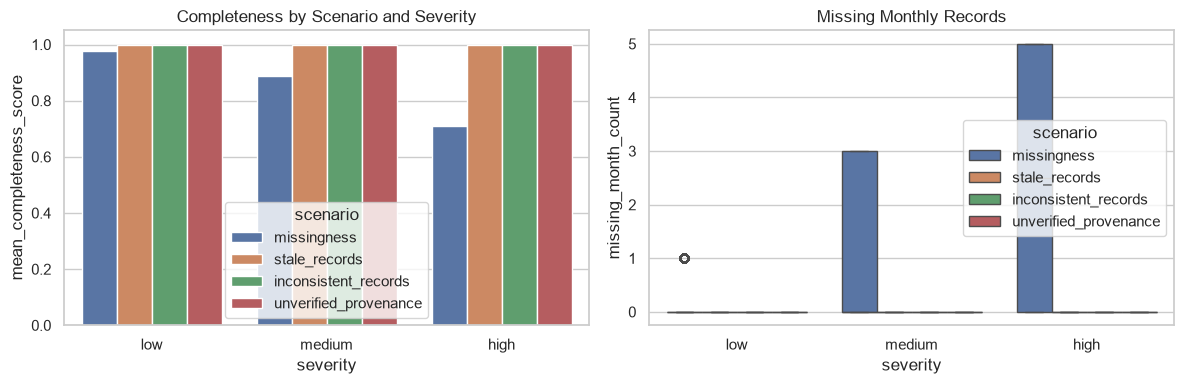

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=summary, x='severity', y='mean_completeness_score', hue='scenario', ax=axes[0])
axes[0].set_title('Completeness by Scenario and Severity')
sns.boxplot(data=quality, x='severity', y='missing_month_count', hue='scenario', ax=axes[1])
axes[1].set_title('Missing Monthly Records')
fig.tight_layout()

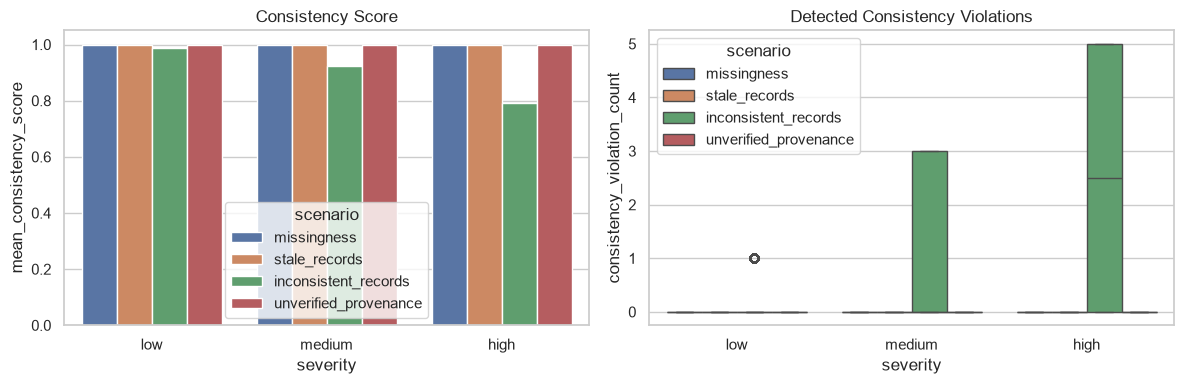

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=summary, x='severity', y='mean_consistency_score', hue='scenario', ax=axes[0])
axes[0].set_title('Consistency Score')
sns.boxplot(data=quality, x='severity', y='consistency_violation_count', hue='scenario', ax=axes[1])
axes[1].set_title('Detected Consistency Violations')
fig.tight_layout()

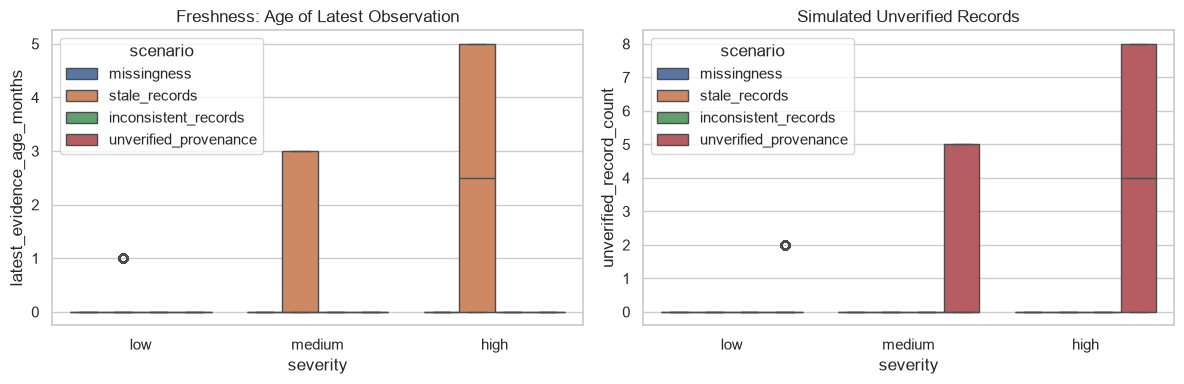

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=quality, x='severity', y='latest_evidence_age_months', hue='scenario', ax=axes[0])
axes[0].set_title('Freshness: Age of Latest Observation')
sns.boxplot(data=quality, x='severity', y='unverified_record_count', hue='scenario', ax=axes[1])
axes[1].set_title('Simulated Unverified Records')
fig.tight_layout()

In [7]:
dimension_columns = ['completeness_score', 'consistency_score', 'freshness_score', 'provenance_score', 'evidence_quality_score']
quality.groupby(['scenario', 'severity'])[dimension_columns].mean().round(4)

completeness_score  consistency_score  \
scenario              severity                                          
inconsistent_records  high                  1.0000             0.7917   
                      low                   1.0000             0.9875   
                      medium                1.0000             0.9250   
missingness           high                  0.7101             1.0000   
                      low                   0.9766             1.0000   
                      medium                0.8891             1.0000   
stale_records         high                  1.0000             1.0000   
                      low                   1.0000             1.0000   
                      medium                1.0000             1.0000   
unverified_provenance high                  1.0000             1.0000   
                      low                   1.0000             1.0000   
                      medium                1.0000             1.0000   

                                freshness_score  provenance_score  \
scenario              severity                                      
inconsistent_records  high               1.0000            1.0000   
                      low                1.0000            1.0000   
                      medium             1.0000            1.0000   
missingness           high               1.0000            1.0000   
                      low                1.0000            1.0000   
                      medium             1.0000            1.0000   
stale_records         high               0.7727            1.0000   
                      low                0.9864            1.0000   
                      medium             0.9182            1.0000   
unverified_provenance high               1.0000            0.6667   
                      low                1.0000            0.9750   
                      medium             1.0000            0.8750   

                                evidence_quality_score  
scenario              severity                          
inconsistent_records  high                      0.9479  
                      low                       0.9969  
                      medium                    0.9812  
missingness           high                      0.9275  
                      low                       0.9942  
                      medium                    0.9723  
stale_records         high                      0.9432  
                      low                       0.9966  
                      medium                    0.9795  
unverified_provenance high                      0.9167  
                      low                       0.9938  
                      medium                    0.9688

## Limitations

All defects are simulated. The unweighted aggregate quality score is a provisional summary, not a calibrated probability or validated real-world evidence-quality measure. These observations do not establish real-world credit-risk validity or prove a future Safety Gate will improve decisions.